# 🏠 Modul 7 — Praktikum Distribusi Normal (Gaussian)

### Studi Kasus: Boston Housing — Normal, CLT, Z-score & Weight Initialization

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)
**Program Studi:** Teknik Informatika (55201) · FTI · Uniska MAB Banjarmasin
**Semester:** 5 · 3 SKS

---

## 🎯 Tujuan Pembelajaran

1. **Memahami** distribusi Normal N(μ, σ²), PDF, dan 68-95-99.7 rule.
2. **Membuktikan** Central Limit Theorem secara empiris dengan bootstrap.
3. **Menerapkan** Z-score standardization + StandardScaler untuk ML preprocessing.
4. **Mengimplementasikan** Xavier/He weight initialization pada MLP regression.

---

## 📋 Alur Notebook

| Bagian | Isi | Waktu |
|--------|-----|-------|
| **A** | Setup & Load Boston Housing | 10 menit |
| **B** | EDA Distribusi Fitur | 10 menit |
| **C** | Normal Fit untuk fitur rm | 10 menit |
| **D** | Verifikasi 68-95-99.7 Rule | 10 menit |
| **E** | Central Limit Theorem Demo | 15 menit |
| **F** | Z-score & StandardScaler | 10 menit |
| **G** | MLP dengan Xavier/He Init | 15 menit |
| **H** | Refleksi & Submit | 10 menit |

**Total: ± 90 menit**

---

## 💡 Kenapa Boston Housing?

Dataset klasik ML dari Kaggle:
- ✅ **506 rumah** di Boston dengan 13 fitur numerik lengkap
- ✅ Fitur `rm` (jumlah kamar) kuasi-Normal — bagus untuk fit Gaussian
- ✅ Fitur `medv` (target) skewed-right — demo CLT dari non-Normal
- ✅ Range skala berbeda (crim 0-89, tax 187-711) — demo StandardScaler
- ✅ Cocok untuk regression → MLP sederhana


---

# 🔧 A. Setup & Load Boston Housing

## A.1 Import Library


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scipy untuk distribusi Normal
from scipy import stats
from scipy.stats import norm, shapiro

# sklearn untuk standardization + MLP
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Library siap untuk Modul 7!")
print(f"NumPy  : {np.__version__}")
print(f"Pandas : {pd.__version__}")


Library siap untuk Modul 7!
NumPy  : 2.1.3
Pandas : 2.2.3


## A.2 Load Dataset dari Kaggle Mirror


In [2]:
# URL dataset Boston Housing
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"

df = pd.read_csv(url)
print(f"Dataset berhasil dimuat!")
print(f"Shape: {df.shape[0]} baris × {df.shape[1]} kolom")
print(f"\nKolom:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col}")
df.head()


Dataset berhasil dimuat!
Shape: 506 baris × 14 kolom

Kolom:
   1. crim
   2. zn
   3. indus
   4. chas
   5. nox
   6. rm
   7. age
   8. dis
   9. rad
  10. tax
  11. ptratio
  12. b
  13. lstat
  14. medv


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


---

# 🔍 B. EDA: Distribusi Fitur

## B.1 Histogram Semua Fitur Numerik


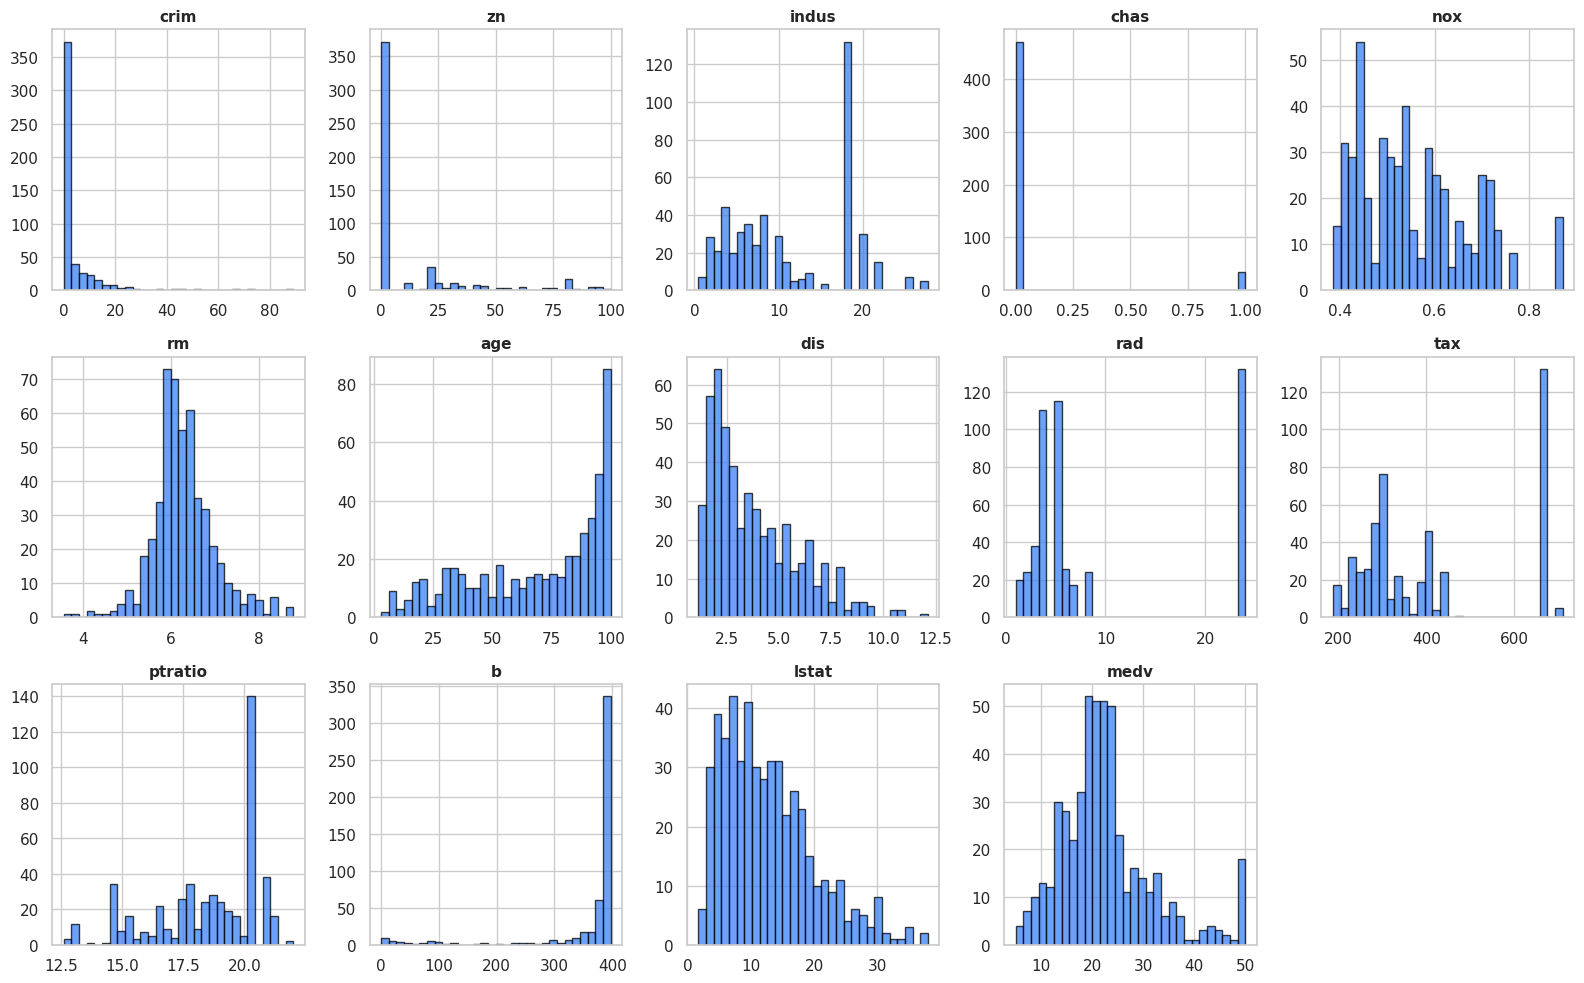

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for i, col in enumerate(df.columns):
    ax = axes[i // 5, i % 5]
    df[col].hist(bins=30, ax=ax, color='#3B82F6', edgecolor='black', alpha=0.75)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_xlabel("")
# Hide extra subplot
if len(df.columns) < 15:
    axes[-1, -1].axis('off')
plt.tight_layout()
plt.show()


## B.2 Skewness Test


In [4]:
skew_summary = pd.DataFrame({
    'mean': df.mean().round(3),
    'std': df.std().round(3),
    'skewness': df.skew().round(3),
    'bentuk': df.skew().apply(lambda s:
        'Kuasi-Normal' if abs(s) < 0.5
        else 'Skewed-right' if s > 0 else 'Skewed-left'),
})
print(skew_summary)
print("\n💡 Fitur 'rm' paling mendekati Normal → dipakai untuk Section C.")
print("💡 Fitur 'medv' (target) skewed → dipakai untuk CLT di Section E.")


            mean      std  skewness        bentuk
crim       3.614    8.602     5.223  Skewed-right
zn        11.364   23.322     2.226  Skewed-right
indus     11.137    6.860     0.295  Kuasi-Normal
chas       0.069    0.254     3.406  Skewed-right
nox        0.555    0.116     0.729  Skewed-right
rm         6.285    0.703     0.404  Kuasi-Normal
age       68.575   28.149    -0.599   Skewed-left
dis        3.795    2.106     1.012  Skewed-right
rad        9.549    8.707     1.005  Skewed-right
tax      408.237  168.537     0.670  Skewed-right
ptratio   18.456    2.165    -0.802   Skewed-left
b        356.674   91.295    -2.890   Skewed-left
lstat     12.653    7.141     0.906  Skewed-right
medv      22.533    9.197     1.108  Skewed-right

💡 Fitur 'rm' paling mendekati Normal → dipakai untuk Section C.
💡 Fitur 'medv' (target) skewed → dipakai untuk CLT di Section E.


---

# 📊 C. Normal Fit untuk fitur `rm`

**Tujuan Pembelajaran 1** — Fit Normal distribution ke data riil.

## C.1 Estimasi Parameter μ, σ (MLE)


In [5]:
rm = df['rm']
mu_hat = rm.mean()
sigma_hat = rm.std(ddof=0)  # MLE: pakai population std

print(f"Estimasi parameter untuk rm:")
print(f"  μ̂ = mean    = {mu_hat:.4f}")
print(f"  σ̂ = std     = {sigma_hat:.4f}")
print(f"  N (sample)  = {len(rm)}")

# Formal normality test (Shapiro-Wilk)
stat_sw, p_sw = shapiro(rm)
print(f"\nShapiro-Wilk test:")
print(f"  W = {stat_sw:.4f}")
print(f"  p = {p_sw:.4e}")
print(f"  Interpretasi: {'Normal' if p_sw > 0.05 else 'Bukan Normal sempurna (tapi tetap bell-shaped)'}")


Estimasi parameter untuk rm:
  μ̂ = mean    = 6.2846
  σ̂ = std     = 0.7019
  N (sample)  = 506

Shapiro-Wilk test:
  W = 0.9609
  p = 2.4120e-10
  Interpretasi: Bukan Normal sempurna (tapi tetap bell-shaped)


## C.2 Plot PDF Overlay Histogram


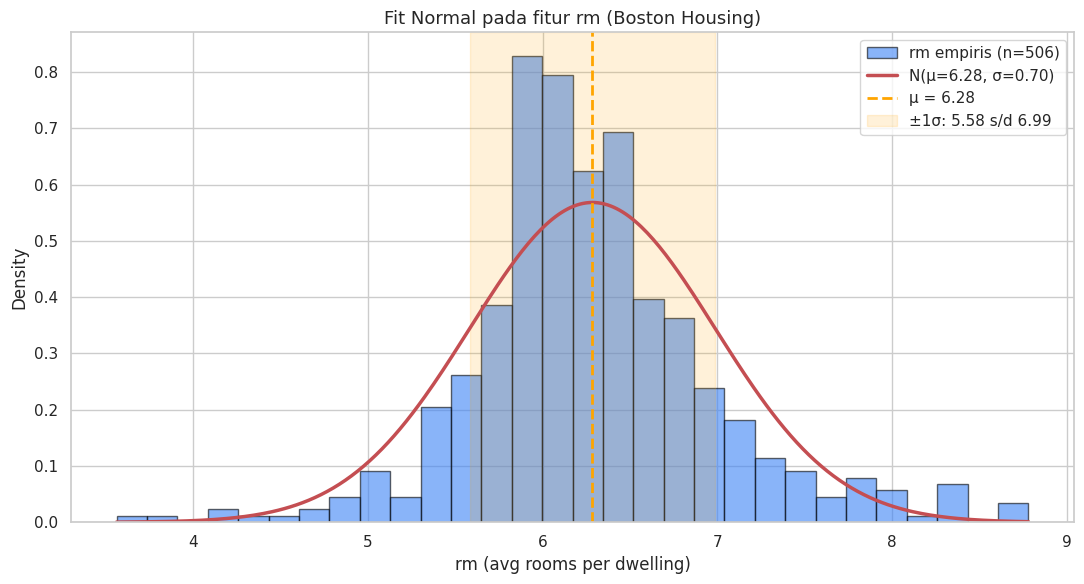

In [6]:
fig, ax = plt.subplots(figsize=(11, 6))

# Histogram empiris
ax.hist(rm, bins=30, density=True, color='#3B82F6', edgecolor='black',
        alpha=0.6, label=f'rm empiris (n={len(rm)})')

# Overlay Normal PDF teoritis
x_range = np.linspace(rm.min(), rm.max(), 300)
pdf_vals = norm.pdf(x_range, loc=mu_hat, scale=sigma_hat)
ax.plot(x_range, pdf_vals, 'r-', linewidth=2.5,
        label=f'N(μ={mu_hat:.2f}, σ={sigma_hat:.2f})')

# Mark μ
ax.axvline(mu_hat, color='orange', linestyle='--', linewidth=2,
           label=f'μ = {mu_hat:.2f}')
ax.axvspan(mu_hat - sigma_hat, mu_hat + sigma_hat, alpha=0.15, color='orange',
           label=f'±1σ: {mu_hat-sigma_hat:.2f} s/d {mu_hat+sigma_hat:.2f}')

ax.set_xlabel('rm (avg rooms per dwelling)', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title(f'Fit Normal pada fitur rm (Boston Housing)', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


## C.3 QQ-Plot untuk Validasi Visual


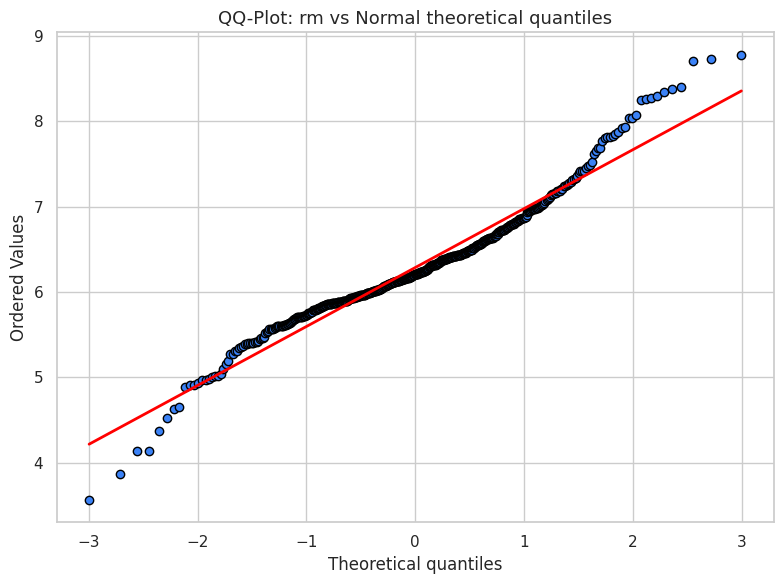


💡 Points dekat garis merah → distribusi mendekati Normal.
   Deviasi di ekor → tail behavior sedikit berbeda dari Normal murni.


In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
stats.probplot(rm, dist="norm", plot=ax)
ax.set_title('QQ-Plot: rm vs Normal theoretical quantiles', fontsize=13)
ax.get_lines()[0].set_markerfacecolor('#3B82F6')
ax.get_lines()[0].set_markeredgecolor('black')
ax.get_lines()[1].set_color('red')
ax.get_lines()[1].set_linewidth(2)
plt.tight_layout()
plt.show()

print("\n💡 Points dekat garis merah → distribusi mendekati Normal.")
print("   Deviasi di ekor → tail behavior sedikit berbeda dari Normal murni.")


---

# 📏 D. Verifikasi Aturan 68-95-99.7

**Tujuan Pembelajaran 1** — Verifikasi three-sigma rule secara empiris pada data riil.


Verifikasi 68-95-99.7 Rule pada rm:
  ±1σ:  empiris = 77.27%  |  teori = 68.27%
  ±2σ:  empiris = 93.68%  |  teori = 95.45%
  ±3σ:  empiris = 98.42%  |  teori = 99.73%


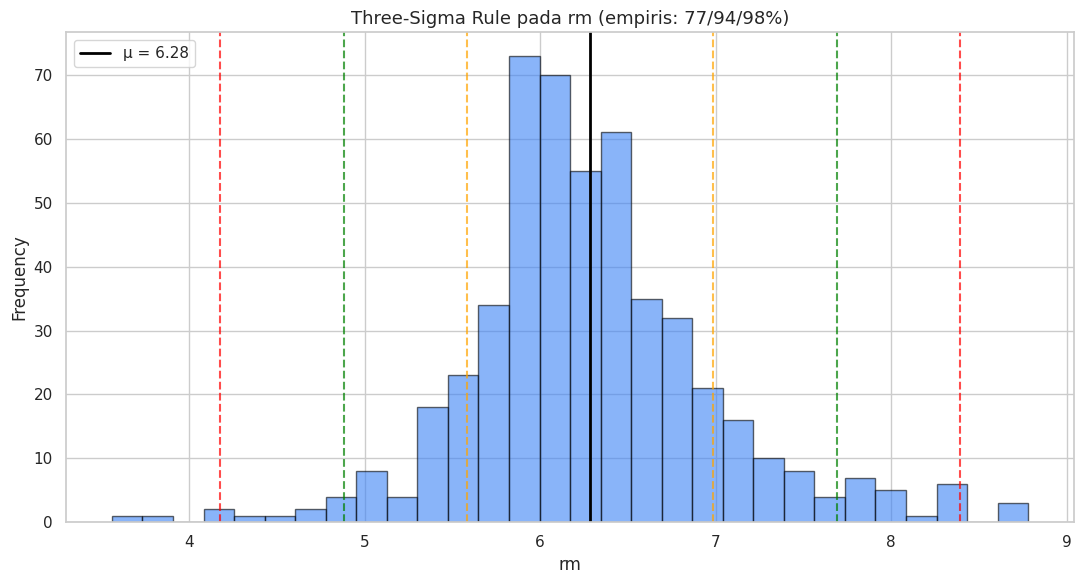

In [8]:
# Hitung proporsi empiris dalam ±1σ, ±2σ, ±3σ
within_1sigma = ((rm >= mu_hat - sigma_hat) & (rm <= mu_hat + sigma_hat)).mean()
within_2sigma = ((rm >= mu_hat - 2*sigma_hat) & (rm <= mu_hat + 2*sigma_hat)).mean()
within_3sigma = ((rm >= mu_hat - 3*sigma_hat) & (rm <= mu_hat + 3*sigma_hat)).mean()

print(f"Verifikasi 68-95-99.7 Rule pada rm:")
print(f"  ±1σ:  empiris = {within_1sigma*100:.2f}%  |  teori = 68.27%")
print(f"  ±2σ:  empiris = {within_2sigma*100:.2f}%  |  teori = 95.45%")
print(f"  ±3σ:  empiris = {within_3sigma*100:.2f}%  |  teori = 99.73%")

# Visualisasi
fig, ax = plt.subplots(figsize=(11, 6))
ax.hist(rm, bins=30, color='#3B82F6', edgecolor='black', alpha=0.6)

for k, label, color in [(1, '±1σ', 'orange'), (2, '±2σ', 'green'), (3, '±3σ', 'red')]:
    ax.axvline(mu_hat - k*sigma_hat, color=color, linestyle='--', linewidth=1.5, alpha=0.7)
    ax.axvline(mu_hat + k*sigma_hat, color=color, linestyle='--', linewidth=1.5, alpha=0.7)

ax.axvline(mu_hat, color='black', linestyle='-', linewidth=2, label=f'μ = {mu_hat:.2f}')
ax.set_xlabel('rm', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Three-Sigma Rule pada rm (empiris: {within_1sigma*100:.0f}/{within_2sigma*100:.0f}/{within_3sigma*100:.0f}%)', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


---

# 🌐 E. Central Limit Theorem Demonstrasi

**Tujuan Pembelajaran 2** — Buktikan secara empiris bahwa mean sampel dari distribusi SKEWED (medv) konvergen ke Normal saat n membesar.

## E.1 Visualisasi Target medv (parent — skewed)


medv statistik:
  Mean     = 22.533
  Std      = 9.197
  Skewness = 1.108  (jauh dari 0 → skewed)


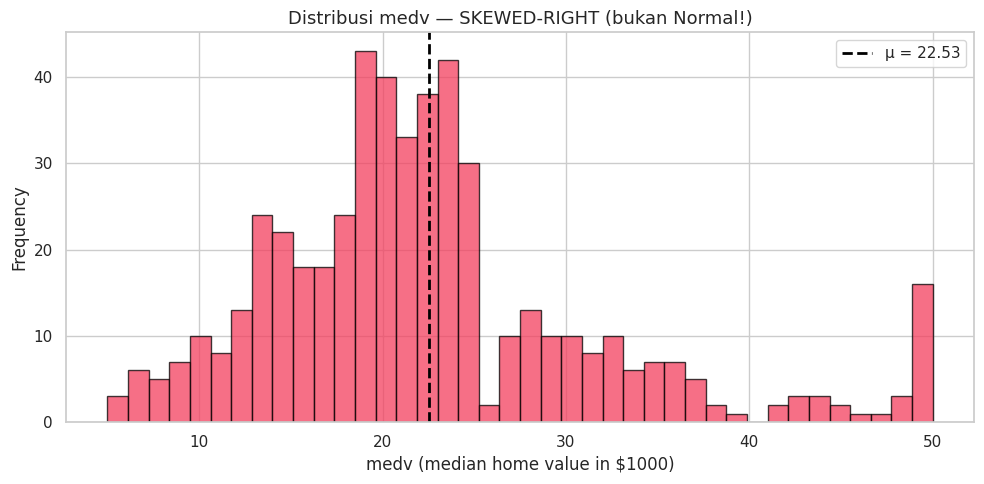

In [9]:
medv = df['medv']
print(f"medv statistik:")
print(f"  Mean     = {medv.mean():.3f}")
print(f"  Std      = {medv.std():.3f}")
print(f"  Skewness = {medv.skew():.3f}  (jauh dari 0 → skewed)")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(medv, bins=40, color='#F43F5E', edgecolor='black', alpha=0.75)
ax.axvline(medv.mean(), color='black', linestyle='--', linewidth=2, label=f'μ = {medv.mean():.2f}')
ax.set_xlabel('medv (median home value in $1000)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Distribusi medv — SKEWED-RIGHT (bukan Normal!)', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


## E.2 Bootstrap Mean untuk n = 5, 30, 100


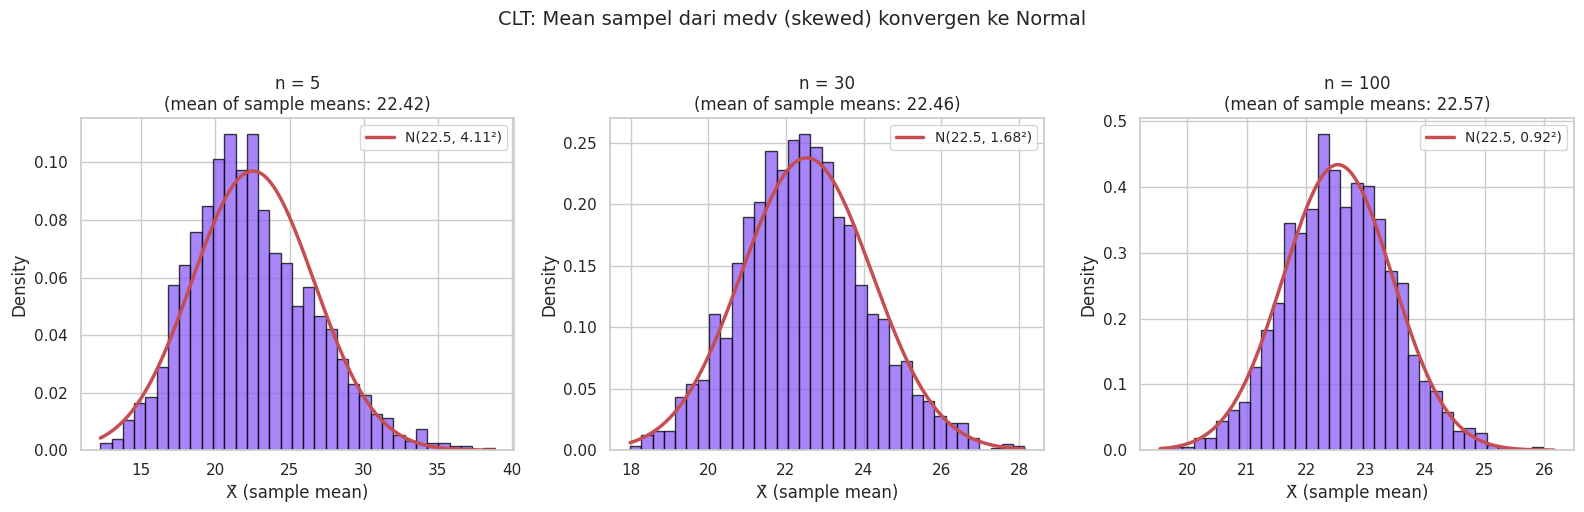


💡 Semakin besar n, distribusi X̄ semakin mendekati Normal — meski parent skewed!
💡 Standard error SE = σ/√n: makin kecil dengan n membesar.


In [10]:
np.random.seed(42)
n_simulations = 2000
sample_sizes = [5, 30, 100]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, n in zip(axes, sample_sizes):
    sample_means = [medv.sample(n=n, replace=True).mean()
                    for _ in range(n_simulations)]
    sample_means = np.array(sample_means)

    # Histogram sample means
    ax.hist(sample_means, bins=35, density=True, color='#8B5CF6',
            edgecolor='black', alpha=0.75)

    # Overlay Normal berdasarkan CLT prediction
    mu_pred = medv.mean()
    se_pred = medv.std() / np.sqrt(n)  # SE = σ/√n
    x = np.linspace(sample_means.min(), sample_means.max(), 200)
    ax.plot(x, norm.pdf(x, mu_pred, se_pred), 'r-', linewidth=2.5,
            label=f'N({mu_pred:.1f}, {se_pred:.2f}²)')

    ax.set_title(f'n = {n}\n(mean of sample means: {sample_means.mean():.2f})', fontsize=12)
    ax.set_xlabel('X̄ (sample mean)')
    ax.set_ylabel('Density')
    ax.legend(fontsize=10)

plt.suptitle(f'CLT: Mean sampel dari medv (skewed) konvergen ke Normal', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("\n💡 Semakin besar n, distribusi X̄ semakin mendekati Normal — meski parent skewed!")
print("💡 Standard error SE = σ/√n: makin kecil dengan n membesar.")


---

# 🎯 F. Z-score Standardization

**Tujuan Pembelajaran 3** — Apply z-transform manual + StandardScaler.

## F.1 Z-score Manual untuk Outlier Detection


In [11]:
# Hitung z-score manual untuk fitur crim (crime rate)
crim = df['crim']
mu_crim, sigma_crim = crim.mean(), crim.std()

z_scores = (crim - mu_crim) / sigma_crim

print(f"Z-score untuk crim:")
print(f"  Mean(z)  = {z_scores.mean():.4f}  (expected ≈ 0)")
print(f"  Std(z)   = {z_scores.std():.4f}   (expected ≈ 1)")

# Outlier detection (|z| > 3)
outliers = df[abs(z_scores) > 3]
print(f"\n🚨 Outlier (|z| > 3): {len(outliers)} baris")
print("Top 5 outlier dengan crim tertinggi:")
print(outliers.nlargest(5, 'crim')[['crim', 'medv']].round(2))


Z-score untuk crim:
  Mean(z)  = -0.0000  (expected ≈ 0)
  Std(z)   = 1.0000   (expected ≈ 1)

🚨 Outlier (|z| > 3): 8 baris
Top 5 outlier dengan crim tertinggi:
      crim  medv
380  88.98  10.4
418  73.53   8.8
405  67.92   5.0
410  51.14  15.0
414  45.75   7.0


## F.2 StandardScaler dengan sklearn


In [12]:
# Pisahkan fitur dan target
X = df.drop('medv', axis=1)
y = df['medv']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit scaler di train, transform ke keduanya
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Sebelum StandardScaler (X_train):")
print(f"  Mean per kolom (sample):\n{X_train.mean().round(2).head()}")
print(f"  Std per kolom (sample) :\n{X_train.std().round(2).head()}")

print("\nSetelah StandardScaler (X_train_scaled):")
print(f"  Mean per kolom (semua) : {X_train_scaled.mean(axis=0).round(4)}")
print(f"  Std per kolom (semua)  : {X_train_scaled.std(axis=0).round(4)}")

print("\n💡 Mean ≈ 0, Std ≈ 1 untuk semua fitur — siap untuk ML!")


Sebelum StandardScaler (X_train):
  Mean per kolom (sample):
crim      3.61
zn       11.57
indus    10.99
chas      0.07
nox       0.56
dtype: float64
  Std per kolom (sample) :
crim      8.88
zn       23.15
indus     6.89
chas      0.26
nox       0.12
dtype: float64

Setelah StandardScaler (X_train_scaled):
  Mean per kolom (semua) : [-0.  0. -0.  0. -0. -0. -0.  0. -0. -0.  0. -0. -0.]
  Std per kolom (semua)  : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

💡 Mean ≈ 0, Std ≈ 1 untuk semua fitur — siap untuk ML!


---

# 🧠 G. MLP Regression dengan Xavier/He Init

**Tujuan Pembelajaran 4** — Train MLP regressor dengan weight init berbeda, bandingkan konvergensi.

## G.1 Baseline MLP tanpa standardization


In [13]:
# Tanpa scaling → biasanya lambat / tidak konvergen baik
mlp_raw = MLPRegressor(hidden_layer_sizes=(32, 16), activation='relu',
                      solver='adam', max_iter=200, random_state=0, early_stopping=False)
mlp_raw.fit(X_train, y_train)
pred_raw = mlp_raw.predict(X_test)
r2_raw = r2_score(y_test, pred_raw)
rmse_raw = np.sqrt(mean_squared_error(y_test, pred_raw))

print(f"MLP tanpa scaling:")
print(f"  R² test   = {r2_raw:.4f}")
print(f"  RMSE test = {rmse_raw:.3f}")


MLP tanpa scaling:
  R² test   = 0.4669
  RMSE test = 6.253


## G.2 MLP dengan Standardization (data normal input + He-init via sklearn default)

sklearn `MLPRegressor` dengan ReLU menggunakan **Glorot/He-style initialization** by default. Kombinasi dengan `StandardScaler` → input mendekati N(0,1), konvergensi jauh lebih stabil.


In [14]:
mlp_scaled = MLPRegressor(hidden_layer_sizes=(32, 16), activation='relu',
                         solver='adam', max_iter=200, random_state=0, early_stopping=False)
mlp_scaled.fit(X_train_scaled, y_train)
pred_scaled = mlp_scaled.predict(X_test_scaled)
r2_scaled = r2_score(y_test, pred_scaled)
rmse_scaled = np.sqrt(mean_squared_error(y_test, pred_scaled))

print(f"MLP dengan StandardScaler:")
print(f"  R² test   = {r2_scaled:.4f}")
print(f"  RMSE test = {rmse_scaled:.3f}")

print(f"\n🎯 Improvement karena input Normal:")
print(f"   R² : {r2_raw:.3f} → {r2_scaled:.3f}  (+{(r2_scaled-r2_raw):.3f})")
print(f"   RMSE: {rmse_raw:.2f} → {rmse_scaled:.2f}  ({(rmse_scaled-rmse_raw):+.2f})")


MLP dengan StandardScaler:
  R² test   = 0.7265
  RMSE test = 4.479

🎯 Improvement karena input Normal:
   R² : 0.467 → 0.726  (+0.260)
   RMSE: 6.25 → 4.48  (-1.77)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


## G.3 Visualisasi: Loss Curve Perbandingan


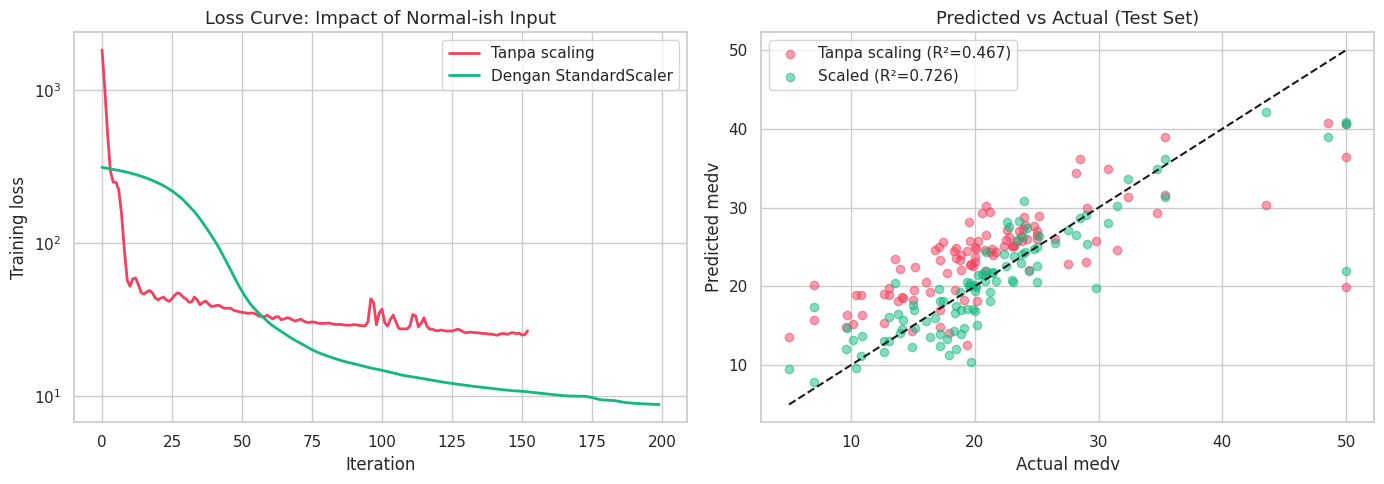


💡 Standardization membuat loss landscape lebih bulat → GD konvergen cepat & stabil.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(mlp_raw.loss_curve_, color='#F43F5E', linewidth=2, label='Tanpa scaling')
axes[0].plot(mlp_scaled.loss_curve_, color='#10B981', linewidth=2, label='Dengan StandardScaler')
axes[0].set_xlabel('Iteration', fontsize=12)
axes[0].set_ylabel('Training loss', fontsize=12)
axes[0].set_title('Loss Curve: Impact of Normal-ish Input', fontsize=13)
axes[0].legend(fontsize=11)
axes[0].set_yscale('log')

# Scatter predicted vs actual
axes[1].scatter(y_test, pred_raw, color='#F43F5E', alpha=0.5, label=f'Tanpa scaling (R²={r2_raw:.3f})')
axes[1].scatter(y_test, pred_scaled, color='#10B981', alpha=0.5, label=f'Scaled (R²={r2_scaled:.3f})')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', linewidth=1.5)
axes[1].set_xlabel('Actual medv', fontsize=12)
axes[1].set_ylabel('Predicted medv', fontsize=12)
axes[1].set_title('Predicted vs Actual (Test Set)', fontsize=13)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

print("\n💡 Standardization membuat loss landscape lebih bulat → GD konvergen cepat & stabil.")


---

# 📝 H. Refleksi & Submit

## H.1 Pertanyaan Refleksi

Jawab 5 pertanyaan berikut di cell markdown di bawah:

1. **Normal Distribution**: Mengapa distribusi `rm` (jumlah kamar) di Boston Housing hampir Normal tetapi tidak sempurna? Kemungkinan apa yang menyebabkan deviasi di ekor?

2. **Three-sigma Rule**: Pada verifikasi aturan 68-95-99.7, apakah proporsi empiris persis sama dengan teori? Mengapa bisa berbeda sedikit?

3. **CLT**: Mengapa parent distribution `medv` yang skewed-right tetap bisa menghasilkan sample means yang Normal pada n = 30? Sebutkan 1 contoh aplikasi CLT di dunia Data Science.

4. **StandardScaler**: Mengapa WAJIB fit scaler hanya di X_train, lalu transform (bukan fit_transform) ke X_test? Apa risikonya jika salah?

5. **Weight Init**: Jika Anda membangun MLP dengan aktivasi ReLU dari nol (pakai PyTorch/TensorFlow), apakah Xavier atau He initialization yang Anda pilih? Jelaskan.

### ✏️ Jawaban Anda:

1. rm adalah hasil gabungan banyak faktor kecil yang saling menjumlah (ukuran rumah, tipe hunian, kondisi wilayah), sehingga bentuknya mendekati lonceng (CLT). Deviasi di ekor bisa disebabkan oleh rumah mewah dengan kamar sangat banyak, unit kecil dengan kamar sangat sedikit, dan campuran beberapa subpopulasi wilayah dalam satu dataset. Selain itu, rm tidak bisa negatif dan nilainya dibulatkan atau dirata-rata. Dengan n = 506, Shapiro-Wilk juga sensitif sehingga deviasi kecil pun menghasilkan p-value kecil.

2. Tidak persis sama, hanya mendekati. Penyebabnya: sampel berhingga (n = 506), data bukan Normal sempurna (ekor sedikit lebih berat atau miring), dan μ̂ serta σ̂ adalah estimasi dari sampel itu sendiri. Selisih beberapa poin persen masih wajar.

3. Menurut CLT, rata-rata n sampel iid dengan varians hingga mendekati N(μ, σ²/n) apa pun bentuk parent-nya. Pada n = 30, skewness sedang seperti medv biasanya sudah teredam cukup baik. Contoh aplikasi: confidence interval dan uji hipotesis untuk rata-rata, seperti A/B testing metrik rata-rata (rata-rata waktu sesi, nilai transaksi).

4. Scaler hanya di-fit pada X_train untuk mencegah data leakage. Jika di-fit pada seluruh data atau pada X_test, mean dan std data uji ikut masuk ke preprocessing, sehingga evaluasi terlalu optimis. Di produksi, data baru juga tidak tersedia saat scaler dilatih. Memakai fit_transform pada X_test membuat skalanya berbeda dari skala yang dipelajari model, sehingga prediksi bisa melenceng.

5. Saya pilih He initialization. ReLU membuat setengah output menjadi nol, sehingga varians aktivasi turun setengah di tiap layer. He memakai Var(w) = 2/n_in untuk mengompensasi hal itu, sehingga varians aktivasi dan gradien stabil antar layer dan tidak mengecil (vanishing) atau membesar (exploding). Xavier (Var(w) = 2/(n_in+n_out)) lebih cocok untuk aktivasi simetris seperti tanh atau sigmoid. Catatan: MLPRegressor di sklearn sebenarnya memakai inisialisasi bergaya Glorot/Xavier, bukan He murni, jadi untuk He yang sebenarnya gunakan PyTorch/TensorFlow.

## H.2 Checklist Submit

Sebelum submit, pastikan:

- [ ] Semua cell code berhasil dijalankan tanpa error
- [ ] Fit Normal pada `rm` sudah menghasilkan μ ≈ 6.28, σ ≈ 0.70
- [ ] Verifikasi 68-95-99.7 menunjukkan proporsi dekat teori
- [ ] CLT bootstrap untuk n=5, 30, 100 muncul 3 panel
- [ ] StandardScaler menghasilkan mean ≈ 0, std ≈ 1
- [ ] MLP dengan scaling R² > tanpa scaling
- [ ] 5 pertanyaan refleksi sudah dijawab
- [ ] Notebook di-rename: `M7-Praktikum-Normal-NamaAnda.ipynb`
- [ ] Upload ke GitHub repository Anda
- [ ] Link GitHub dikumpulkan via LMS Uniska

## H.3 Push ke GitHub

**Melalui Web:**
1. Buka repository `statistika-probabilitas-uniska` di GitHub Anda.
2. Klik folder `notebooks/`, lalu **Add file → Upload files**.
3. Drag & drop file notebook.
4. Commit message: `"Add Modul 7: Distribusi Normal & CLT"`.
5. Klik **Commit changes**.

---

## 🎓 Selamat! Anda Berhasil...

✅ Fit distribusi Normal ke data riil Boston Housing
✅ Verifikasi aturan 68-95-99.7 secara empiris
✅ Membuktikan CLT dengan bootstrap mean dari distribusi skewed
✅ Apply StandardScaler untuk ML preprocessing
✅ Train MLP regressor dengan weight init yang tepat

## 📚 Bacaan Lanjutan

- **Bruce, P.** (2020). *Practical Statistics for Data Scientists*, Chapter 2.7-2.9 (Normal & CLT).
- **Glorot, X. & Bengio, Y.** (2010). *Understanding the difficulty of training deep feedforward neural networks* (Xavier init paper).
- **He, K. et al.** (2015). *Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification* (He init paper).
- **StatQuest YouTube** — "Normal Distribution Clearly Explained" dan "Central Limit Theorem".

## 🔮 Persiapan Modul 8 & UTS

Modul 8 adalah **Review & UTS CPMK032** (bobot 20%):
- Review Modul 1-6 (M1 Data, M2 Prob, M3 Bayes, M4 RV, M5 Diskret, M7 Normal)
- Solving 10 soal UTS tahun lalu bersama
- Konsultasi project Kaggle

**Sebelum UTS:**
1. **QUIZ 2** (bobot 6%) di akhir Modul 7 — materi: Modul 5 + 6
2. Selesaikan Modul-7.ipynb, push ke GitHub
3. Baca Bruce Ch. 2.7-2.9
4. Buat cheatsheet pribadi untuk Modul 1-6

---

*Notebook by: Prodi Teknik Informatika · Uniska MAB Banjarmasin · Edisi 2026*
